销售订单统计分析

In [126]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from pandas import Series

In [127]:
# 展示中文
plt.rcParams['font.sans-serif'] = ['SimHei']

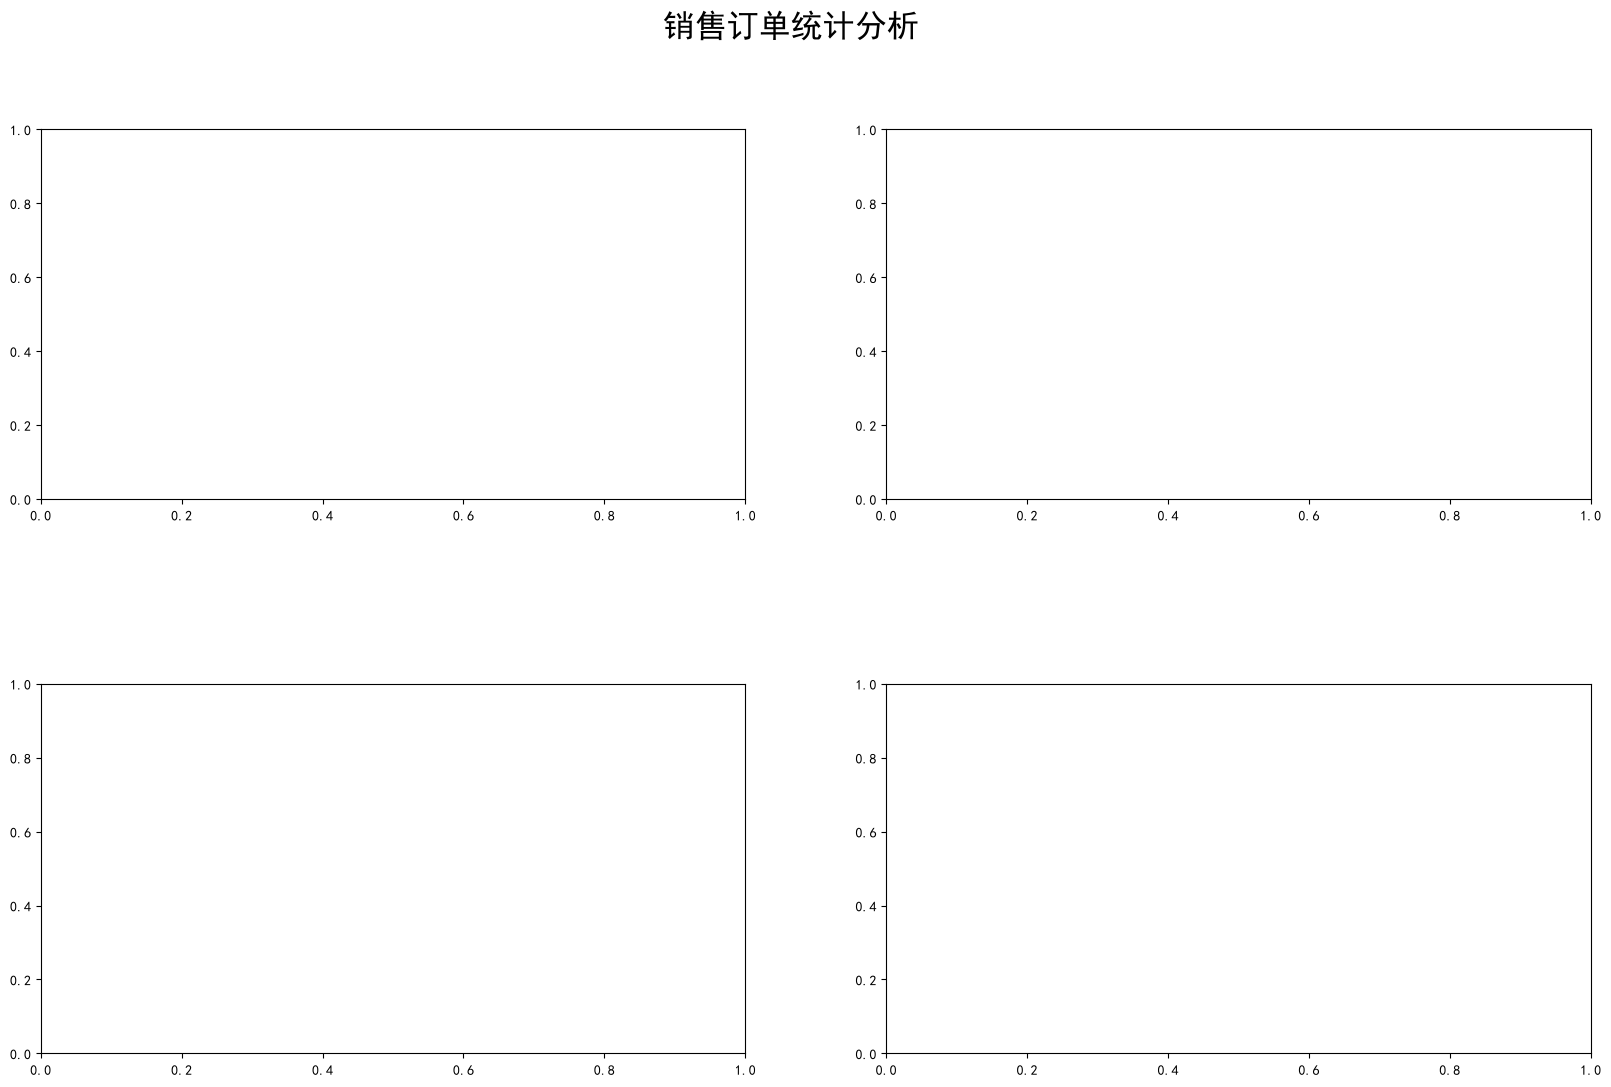

In [128]:
"""
创建子图布局
"""
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12), dpi=100)
fig.suptitle('销售订单统计分析', fontsize=23, x=0.5, y=0.98)
fig.subplots_adjust(hspace=0.5, wspace=0.2)

axes1: Axes = axes[0][0]
axes2: Axes = axes[0][1]
axes3: Axes = axes[1][0]
axes4: Axes = axes[1][1]

In [129]:
df = pd.read_csv('sales.csv',usecols=['订单号', '产品类别', '产品名称', '销售数量', '单价', '客户所在城市', '支付方式', '订单日期'], dtype={'年份':'Int64'})
df

,订单号,产品类别,产品名称,销售数量,单价,客户所在城市,支付方式,订单日期
0,6805677496,家居用品,枕头,10,199,合肥,支付宝,2025-06-01
1,5857234132,食品,海苔,5,29,天津,现金,2025-06-01
2,5888085059,电子产品,智能音箱,5,399,福州,微信支付,2025-06-01
3,6823473137,食品,面包,3,29,北京,银行卡,2025-06-02
4,6801664364,食品,薯片,2,19,NaN,微信支付,2025-06-02
...,...,...,...,...,...,...,...,...
995,5887473055,图书,小说,10,49,长沙,微信支付,2026-03-20
996,5808511756,食品,坚果,2,79,成都,支付宝,2026-03-20
997,5811169466,服装,围巾,4,129,南京,支付宝,2026-03-20
998,6876456690,食品,果汁,7,39,广州,支付宝,2026-03-20


统计每天销售额的变化

In [130]:
# 分组统计
df['销售金额'] = df['销售数量'] * df['单价']

# # 组装数据
# min_year = year_count.index.min()
# max_year = year_count.index.max()
# x = [i for i in range(min_year, max_year+1)]
# y = [int(year_count.get(i, 0)) for i in x]
x = df.groupby('订单日期')['销售金额'].sum().index.to_list()
y = df.groupby('订单日期')['销售金额'].sum().values

In [131]:
"""
绘制每天销售金额变化折线图
"""
axes1.plot(x, y, color='green')
axes1.set_title('每天销售金额变化折线图', fontsize=15)
axes1.set_xlabel('日期', fontsize=12)
axes1.set_ylabel('销售金额', fontsize=12)
    
axes1.set_xticks(x[::15])
axes1.grid(linestyle='--', alpha=0.5)
axes1.tick_params(axis='x', rotation=45)

统计对比不同城市的销售数量

In [132]:
# 组装数据
sales_amount = df.groupby('客户所在城市')['销售数量'].sum().sort_values(ascending=False)
# y = df.groupby('销售数量')['销售数量'].count().values
x = sales_amount.index.to_list()
y = sales_amount.values
y

array([345, 333, 331, 326, 316, 315, 301, 299, 292, 276, 268, 264, 255,
       247, 245, 240, 234, 228, 211, 211])

In [133]:
axes2.bar(x, y, color='blue', width=0.6)
axes2.set_title('不同城市的销售数量柱状图', fontsize=15)
axes2.set_xlabel('城市', fontsize=12)
axes2.set_ylabel('销售数量', fontsize=12)
axes2.grid(linestyle='--', alpha=0.5)
axes2.tick_params(axis='x', rotation=90)

统计不同产品类型对应的订单比例

In [153]:
# ========== 关键：清空这个子图上所有旧内容 ==========
axes3.clear()   
df['产品类别'] = df['产品类别'].str.strip()
cate_amount = df.groupby('产品类别')['销售数量'].sum()
"""
绘制不同产品类型销售数量占比饼状图
"""
axes3.pie(cate_amount.values, labels=cate_amount.index, autopct='%1.1f%%', startangle=0, radius=1.2,textprops={'fontsize': 20}) # autopct='%1.1f%%'
axes3.set_title('不同产品类型对应的订单比例饼状图', fontsize=15,pad =20)
axes3.legend(loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.2))


统计不同支付方式对应的订单比例。（饼状图）

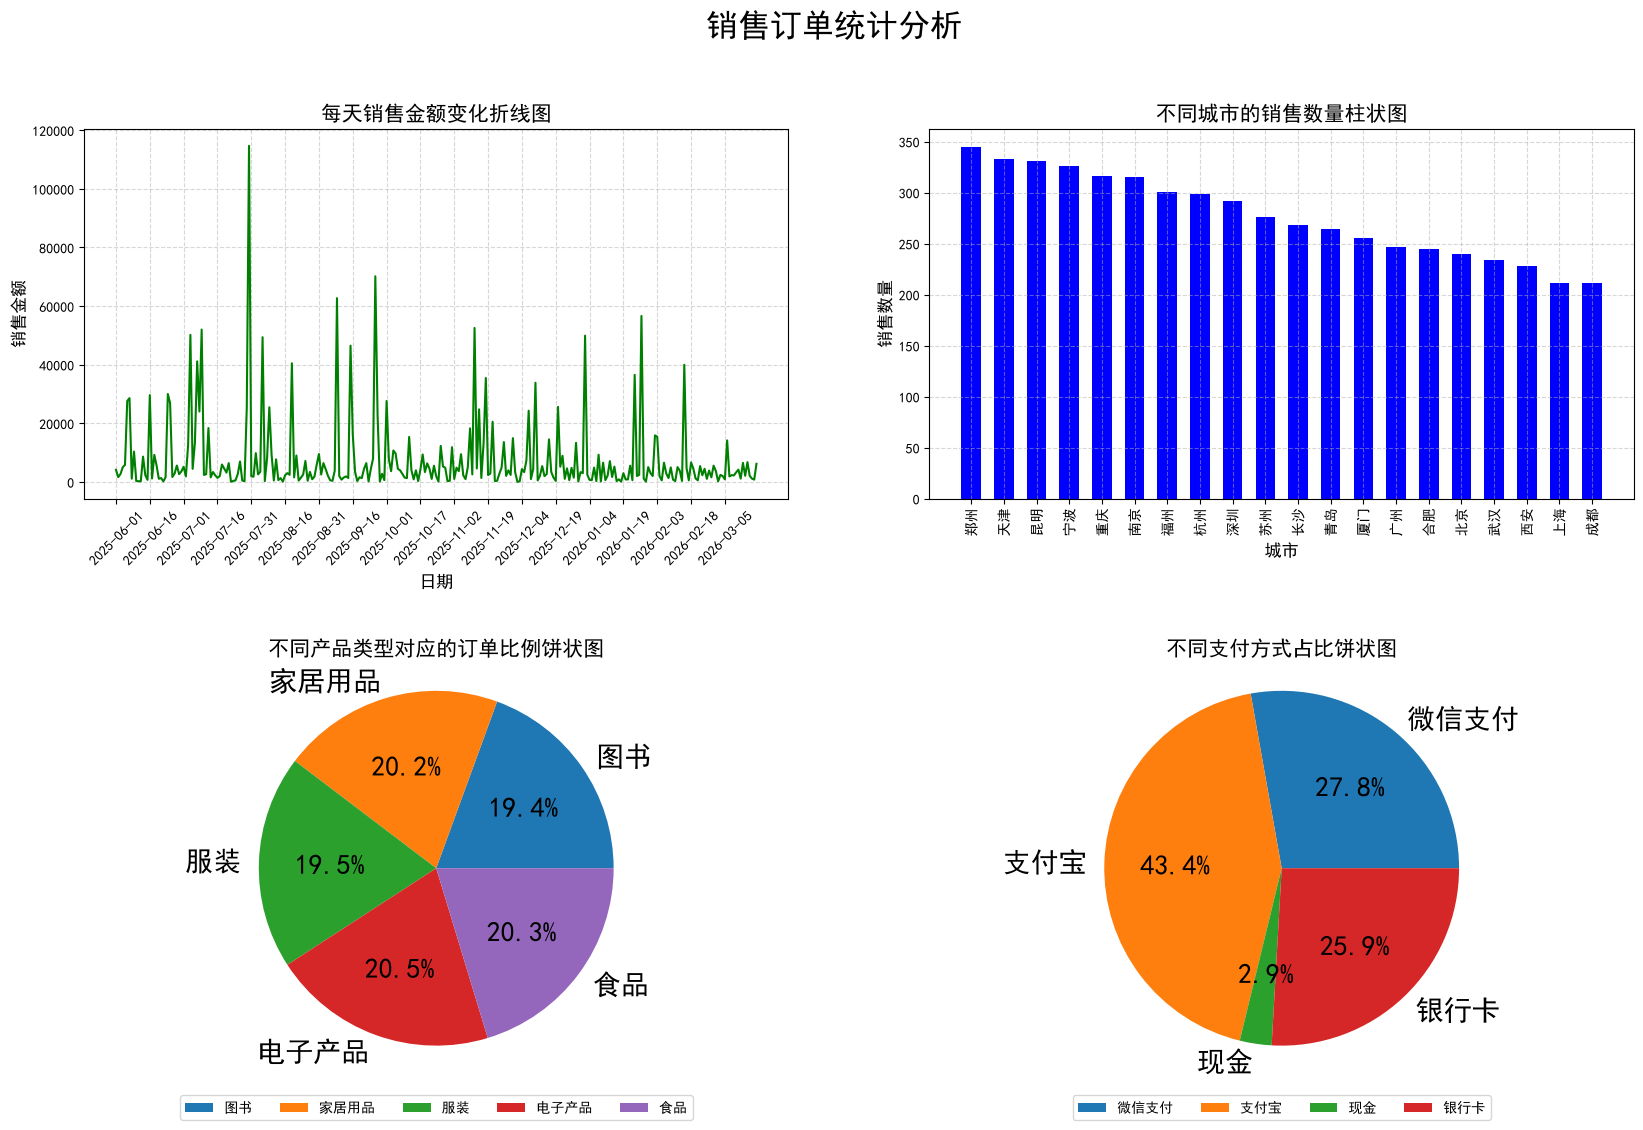

In [156]:
# ========== 关键：清空这个子图上所有旧内容 ==========
axes4.clear()   
pay_method = df.groupby('支付方式')['支付方式'].count()
"""
绘制不同支付方式销售数量占比饼状图
"""
axes4.pie(pay_method.values, labels=pay_method.index, autopct='%1.1f%%', startangle=0, radius=1.2,textprops={'fontsize': 20}) # autopct='%1.1f%%'
axes4.set_title('不同支付方式占比饼状图', fontsize=15,pad =20)
axes4.legend(loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.2))
fig.savefig('销售订单统计分析.png', dpi=100, bbox_inches='tight')
fig